# **Laboratorio** # **4 — Minería de Datos**
**Integrantes del grupo:**
- López Rodríguez Lucas
- Murillo Cruz Sheyla Daliana
- Oporta Rosales Mauricio
- Sancho Ruiz Justin


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

###  **Carga de los conjuntos de datos desde Git en Google Colab** #

In [3]:
url_repo = "https://raw.githubusercontent.com/sheylamurillo/laboratorio4_conjunto-de-datos/main/"
url_lfs = "https://media.githubusercontent.com/media/sheylamurillo/laboratorio4_conjunto-de-datos/main/"

def cargar_csv(archivo, usa_lfs=False, nrows=None):
    url = (url_lfs if usa_lfs else url_repo) + archivo
    df = pd.read_csv(url, nrows=nrows)
    return df

df_movies = cargar_csv("movies.csv", usa_lfs=False)
df_ratings = cargar_csv("ratings.csv", usa_lfs=True, nrows=500000)

###  **Visualizar características básicas** #
* **movies.csv:** Cuenta con **62,423 filas** y **3 columnas** (movieId en int64, y title y genres en object). Presenta **62,325** títulos únicos (con The Forest (2016) repitiéndose 2 veces) y **1,639** combinaciones de géneros únicas, siendo Drama la más frecuente (9,056 registros).
* **ratings.csv:** Evaluado sobre una muestra de **500,000 filas** y **4 columnas** (userId, movieId y timestamp en int64, y rating en float64). La variable rating se encuentra entre **0.5** y **5.0**, con media de **3.55**, mediana de **4.00**.

In [4]:
def explorar(df, nombre):

    print(f"Conjunto de datos: {nombre}")

    # Total de registros de filas y columnas
    print(f"Cantidad de (filas, columnas): {df.shape}\n")

    # Primeros registros para verificar estructura y valores
    print("--- Primeras 5 filas ---")
    display(df.head())

    # Tipos de datos por columna y cantidad de valores no nulos
    print("\n--- Información de columnas y tipos de datos ---")
    df.info()

    # Medidas de tendencia central, dispersión y frecuencias generales
    print("\n--- Medidas de tendencia central, dispersión y frecuencias generales ---")
    display(df.describe(include="all"))


explorar(df_movies, "df_movies (movies.csv)")
explorar(df_ratings, "df_ratings (ratings.csv)")

Conjunto de datos: df_movies (movies.csv)
Cantidad de (filas, columnas): (62423, 3)

--- Primeras 5 filas ---


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



--- Información de columnas y tipos de datos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62423 entries, 0 to 62422
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  62423 non-null  int64 
 1   title    62423 non-null  object
 2   genres   62423 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.4+ MB

--- Medidas de tendencia central, dispersión y frecuencias generales ---


,movieId,title,genres
count,62423.000000,62423,62423
unique,NaN,62325,1639
top,NaN,The Forest (2016),Drama
freq,NaN,2,9056
mean,122220.387646,NaN,NaN
std,63264.744844,NaN,NaN
min,1.000000,NaN,NaN
25%,82146.500000,NaN,NaN
50%,138022.000000,NaN,NaN
75%,173222.000000,NaN,NaN


Conjunto de datos: df_ratings (ratings.csv)
Cantidad de (filas, columnas): (500000, 4)

--- Primeras 5 filas ---


,userId,movieId,rating,timestamp
0,1,296,5.0,1147880044
1,1,306,3.5,1147868817
2,1,307,5.0,1147868828
3,1,665,5.0,1147878820
4,1,899,3.5,1147868510



--- Información de columnas y tipos de datos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     500000 non-null  int64  
 1   movieId    500000 non-null  int64  
 2   rating     500000 non-null  float64
 3   timestamp  500000 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 15.3 MB

--- Medidas de tendencia central, dispersión y frecuencias generales ---


,userId,movieId,rating,timestamp
count,500000.000000,500000.000000,500000.000000,5.000000e+05
mean,1745.358206,20637.567424,3.549066,1.206606e+09
std,976.020643,38556.390766,1.055825,2.295781e+08
min,1.000000,1.000000,0.500000,7.896520e+08
25%,897.000000,1131.000000,3.000000,9.956829e+08
50%,1751.000000,2792.000000,4.000000,1.176779e+09
75%,2580.000000,7934.000000,4.000000,1.444217e+09
max,3445.000000,208939.000000,5.000000,1.574254e+09


### **Cambiar nombres de columnas a español** #

In [5]:
# Columnas de movies a español
df_movies = df_movies.rename(columns={
    "movieId": "id_pelicula",
    "title": "titulo",
    "genres": "generos"
})

# Columnas de ratings a español
df_ratings = df_ratings.rename(columns={
    "userId": "id_usuario",
    "movieId": "id_pelicula",
    "rating": "calificacion",
    "timestamp": "fecha_hora"
})


print("Columnas movies:", df_movies.columns.tolist())
print("Columnas ratings:", df_ratings.columns.tolist())

Columnas movies: ['id_pelicula', 'titulo', 'generos']
Columnas ratings: ['id_usuario', 'id_pelicula', 'calificacion', 'fecha_hora']


###  **Detectar nulos y generar evidencia gráfica** #
Se evaluaron df_movies y df_ratings en busca de valores nulos y cadenas vacías/espacios y se confirmaron **0 valores nulos**  y **0 cadenas vacías** en todas las columnas de ambos conjuntos. La verificación se realizó sobre el total de registros de df_ratings (**25,000,095** datos), manteniendo el mismo resultado de 0 nulos, y para fines gráficos y de practicidad se trabajó con una muestra de **500,000 datos**.

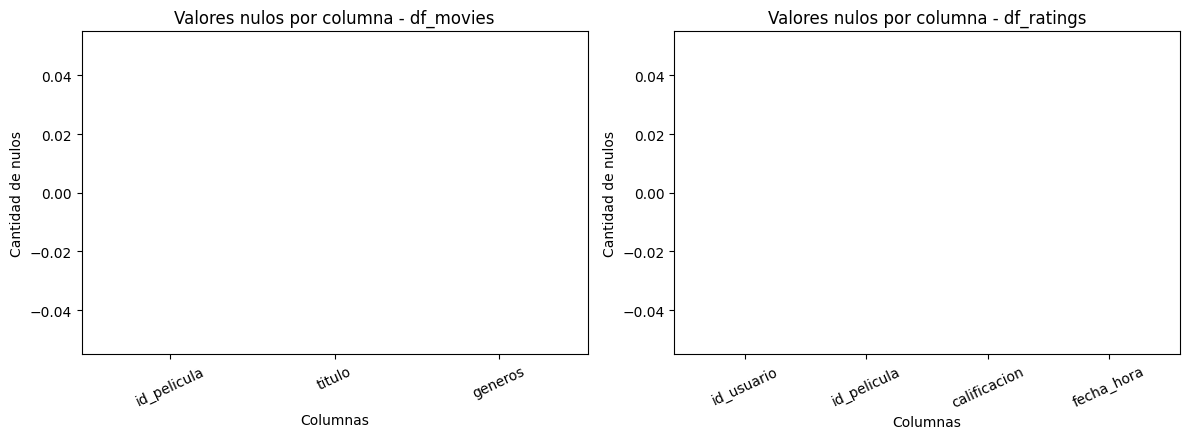

In [6]:
nulos_movies = df_movies.isnull().sum().to_frame(name="valores_nulos")
nulos_ratings = df_ratings.isnull().sum().to_frame(name="valores_nulos")
# --- Grafica de barras
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico de barras de nulos en df_movies
axes[0].bar(nulos_movies.index, nulos_movies["valores_nulos"], color="skyblue")
axes[0].set_title("Valores nulos por columna - df_movies")
axes[0].set_xlabel("Columnas")
axes[0].set_ylabel("Cantidad de nulos")
axes[0].tick_params(axis="x", rotation=25)

# Gráfico de barras de nulos en df_ratings
axes[1].bar(nulos_ratings.index, nulos_ratings["valores_nulos"], color="skyblue")
axes[1].set_title("Valores nulos por columna - df_ratings")
axes[1].set_xlabel("Columnas")
axes[1].set_ylabel("Cantidad de nulos")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

### **Valores atípicos con evidencia gráfica**

Calculando los cuartiles sobre calificacion se obtuvo **Q1 =** 3.00 y **Q3 =** 4.00 **IQR =** 1.00. Al aplicar la regla de Tukey, los límites resultaron en **1.50** (inferior) y **5.50** (superior), marcando **22,012 registros** por debajo del límite inferior (notas de 0.5 y 1.0) y **0** por encima del superior.

* **Boxplot:** Muestra el grueso central entre 3.0 y 4.0, los límites de 1.50 (rojo) y 5.50 (verde), y los puntos aislados en 0.5 y 1.0.
* **Histograma:** Evidencia mayor concentración entre 3.0 y 5.0 y menor frecuencia en las notas bajas.


Q1 = 3.00 | Q3 = 4.00 | IQR = 1.00
Límites IQR = [1.50, 5.50]
Fuera de rango IQR = 22012


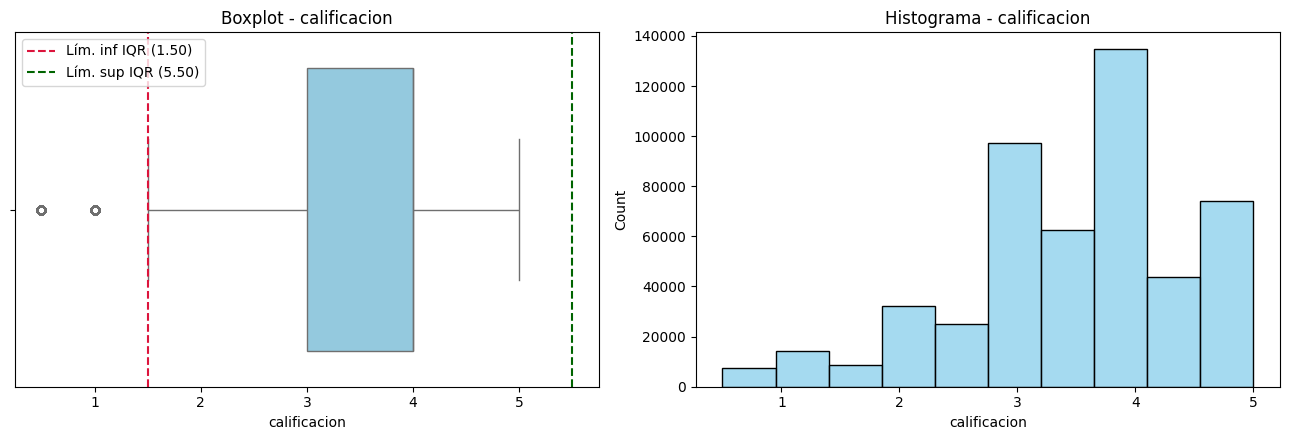

In [7]:
# Variable numérica de df_ratings
col = "calificacion"

# Cálculo del IQR
q1 = df_ratings[col].quantile(0.25)
q3 = df_ratings[col].quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

atipicos_iqr = df_ratings[(df_ratings[col] < lim_inf) | (df_ratings[col] > lim_sup)][col]
print(f"Q1 = {q1:.2f} | Q3 = {q3:.2f} | IQR = {iqr:.2f}")
print(f"Límites IQR = [{lim_inf:.2f}, {lim_sup:.2f}]")
print(f"Fuera de rango IQR = {len(atipicos_iqr)}")

# Boxplot e Histograma
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(x=df_ratings[col], ax=axes[0], color="skyblue")
axes[0].axvline(lim_inf, color="crimson", linestyle="--", label=f"Lím. inf IQR ({lim_inf:.2f})")
axes[0].axvline(lim_sup, color="darkgreen", linestyle="--", label=f"Lím. sup IQR ({lim_sup:.2f})")
axes[0].set_title(f"Boxplot - {col}")
axes[0].legend()

sns.histplot(df_ratings[col], bins=10, kde=False, ax=axes[1], color="skyblue")
axes[1].set_title(f"Histograma - {col}")

plt.tight_layout()
plt.show()